# Listening Test Analysis — From Anonymized Dataset

This notebook replicates the analysis of `collected_runs_analysis.ipynb` but reads
from the **anonymized, publication-ready** dataset in `dataset/listeners_data/`.

Each participant has one CSV file with pre-parsed, PII-free data.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as sp_stats

plt.rcParams.update({
    'font.family':        'Fira Code',
    'font.sans-serif':    ['Fira Code'],
    'font.monospace':     ['Fira Code'],
    'axes.titlesize':     13,
    'axes.labelsize':     11,
    'xtick.labelsize':    9,
    'ytick.labelsize':    9,
    'legend.fontsize':    9,
    'legend.title_fontsize': 10,
    'mathtext.fontset':   'custom',
    'mathtext.rm':        'Fira Code',
    'mathtext.it':        'Fira Code:italic',
    'mathtext.bf':        'Fira Code:bold',
})

pd.set_option('display.max_columns', 120)
pd.set_option('display.width', 180)

In [4]:
DATA_DIR = Path('../dataset/listeners_data')
csv_files = sorted(DATA_DIR.glob('participant_*.csv'))

print(f'Found {len(csv_files)} participant file(s) in {DATA_DIR}')
for f in csv_files:
    print(' -', f.name)

if not csv_files:
    raise FileNotFoundError(f'No participant CSV files found in {DATA_DIR}')

Found 31 participant file(s) in ../dataset/listeners_data
 - participant_001.csv
 - participant_002.csv
 - participant_003.csv
 - participant_004.csv
 - participant_005.csv
 - participant_006.csv
 - participant_007.csv
 - participant_008.csv
 - participant_009.csv
 - participant_010.csv
 - participant_011.csv
 - participant_012.csv
 - participant_013.csv
 - participant_014.csv
 - participant_015.csv
 - participant_016.csv
 - participant_017.csv
 - participant_018.csv
 - participant_019.csv
 - participant_020.csv
 - participant_021.csv
 - participant_022.csv
 - participant_023.csv
 - participant_024.csv
 - participant_025.csv
 - participant_026.csv
 - participant_027.csv
 - participant_028.csv
 - participant_029.csv
 - participant_030.csv
 - participant_031.csv


In [5]:
frames = []
for path in csv_files:
    dfi = pd.read_csv(path, dtype=str, keep_default_na=False)
    frames.append(dfi)

df = pd.concat(frames, ignore_index=True)
print('Rows:', len(df))
print('Columns:', list(df.columns))
print('Participants:', df['participant_id'].nunique())

Rows: 1043
Columns: ['participant_id', 'trial_name', 'time_elapsed_ms', 'response_time_ms', 'age', 'gender', 'microtonal_experience', 'selected_progression', 'is_correct', 'expertise_level', 'chord_num', 'chord_category', 'chord_name', 'dissonance_rating', 'progression_id', 'progression', 'coherence_rating', 'musicality_rating', 'novelty_rating', 'exit_comments', 'exit_difficulties']
Participants: 31


In [6]:
# Overview
print('Trial type counts:')
print(df['trial_name'].value_counts(dropna=False))

print(f'\nRows per participant:')
print(df.groupby('participant_id').size().describe())

Trial type counts:
chord_dissonance     620
chord_progression    301
demographics          31
screening             31
expertise             31
exit_survey           29
Name: trial_name, dtype: int64

Rows per participant:
count    31.000000
mean     33.645161
std       1.799044
min      24.000000
25%      34.000000
50%      34.000000
75%      34.000000
max      34.000000
dtype: float64


In [7]:
# ── Build analysis table ──
# Part 1: chord_dissonance rows
part1 = df[df['trial_name'] == 'chord_dissonance'].copy()
part1['rating'] = pd.to_numeric(part1['dissonance_rating'], errors='coerce')
part1['chord_num'] = pd.to_numeric(part1['chord_num'], errors='coerce')
part1['question_kind'] = 'part1_chord_dissonance'
part1['study_block'] = 'part1_isolated_chords'
part1['rt_ms'] = pd.to_numeric(part1['response_time_ms'], errors='coerce')

# Part 2: chord_progression rows — expand into one row per dimension
part2_raw = df[df['trial_name'] == 'chord_progression'].copy()
part2_raw['rt_ms'] = pd.to_numeric(part2_raw['response_time_ms'], errors='coerce')

dim_map = {
    'coherence_rating': 'part2_coherence',
    'musicality_rating': 'part2_musicality',
    'dissonance_rating': 'part2_dissonance',
    'novelty_rating': 'part2_novelty',
}

part2_rows = []
for _, row in part2_raw.iterrows():
    for col, qk in dim_map.items():
        rr = row.copy()
        rr['question_kind'] = qk
        rr['rating'] = pd.to_numeric(row[col], errors='coerce') if row[col] != '' else np.nan
        rr['study_block'] = 'part2_progressions'
        part2_rows.append(rr)

part2 = pd.DataFrame(part2_rows) if part2_rows else pd.DataFrame()

analysis = pd.concat([part1, part2], ignore_index=True, sort=False)

print('Rows after expansion:')
print('  Part 1:', len(part1))
print('  Part 2:', len(part2))
print('  Total :', len(analysis))
print('\nQuestion-kind counts:')
print(analysis['question_kind'].value_counts(dropna=False))

Rows after expansion:
  Part 1: 620
  Part 2: 1204
  Total : 1824

Question-kind counts:
part1_chord_dissonance    620
part2_coherence           301
part2_musicality          301
part2_dissonance          301
part2_novelty             301
Name: question_kind, dtype: int64


In [8]:
# Global numeric summary
summary_cols = ['rating', 'rt_ms']
print('Global numeric summary (all listening responses):')
print(analysis[summary_cols].describe())

print('\nBy study block (Part 1 vs Part 2):')
grp = analysis.groupby('study_block')[summary_cols].agg(['count', 'mean', 'std', 'median'])
print(grp)

# Part 1 by category
p1 = analysis[(analysis['question_kind'] == 'part1_chord_dissonance') & analysis['rating'].notna()].copy()
print('\nPart 1 (isolated chords): mean dissonance by category')
if len(p1):
    cat = p1.groupby('chord_category')['rating'].agg(['count', 'mean', 'std']).sort_values('mean', ascending=False)
    print(cat)

# Part 2 by dimension
p2 = analysis[(analysis['study_block'] == 'part2_progressions') & analysis['rating'].notna()].copy()
print('\nPart 2 (progressions):')
if len(p2):
    print(p2.groupby('question_kind')['rating'].agg(['count', 'mean', 'std', 'median']).sort_values('mean', ascending=False))

Global numeric summary (all listening responses):
            rating         rt_ms
count  1824.000000  1.824000e+03
mean      5.973136  3.751428e+04
std       2.645407  2.449310e+05
min       1.000000  3.282000e+03
25%       4.000000  6.813750e+03
50%       6.000000  1.633400e+04
75%       8.000000  2.715000e+04
max      10.000000  4.634018e+06

By study block (Part 1 vs Part 2):
                      rating                            rt_ms                                      
                       count      mean       std median count          mean            std   median
study_block                                                                                        
part1_isolated_chords    620  5.429032  2.702203    5.0   620   7281.464516   13426.719229   4869.5
part2_progressions      1204  6.253322  2.572270    6.0  1204  53082.667774  300171.544392  21790.0

Part 1 (isolated chords): mean dissonance by category
                count      mean       std
chord_category      

findfont: Font family ['Fira Code'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Fira Code'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Fira Code'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Fira Code'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Fira Code'] not found. Falling back to DejaVu Sans.


FileNotFoundError: [Errno 2] No such file or directory: 'Figures/Part_2_Rating.png'

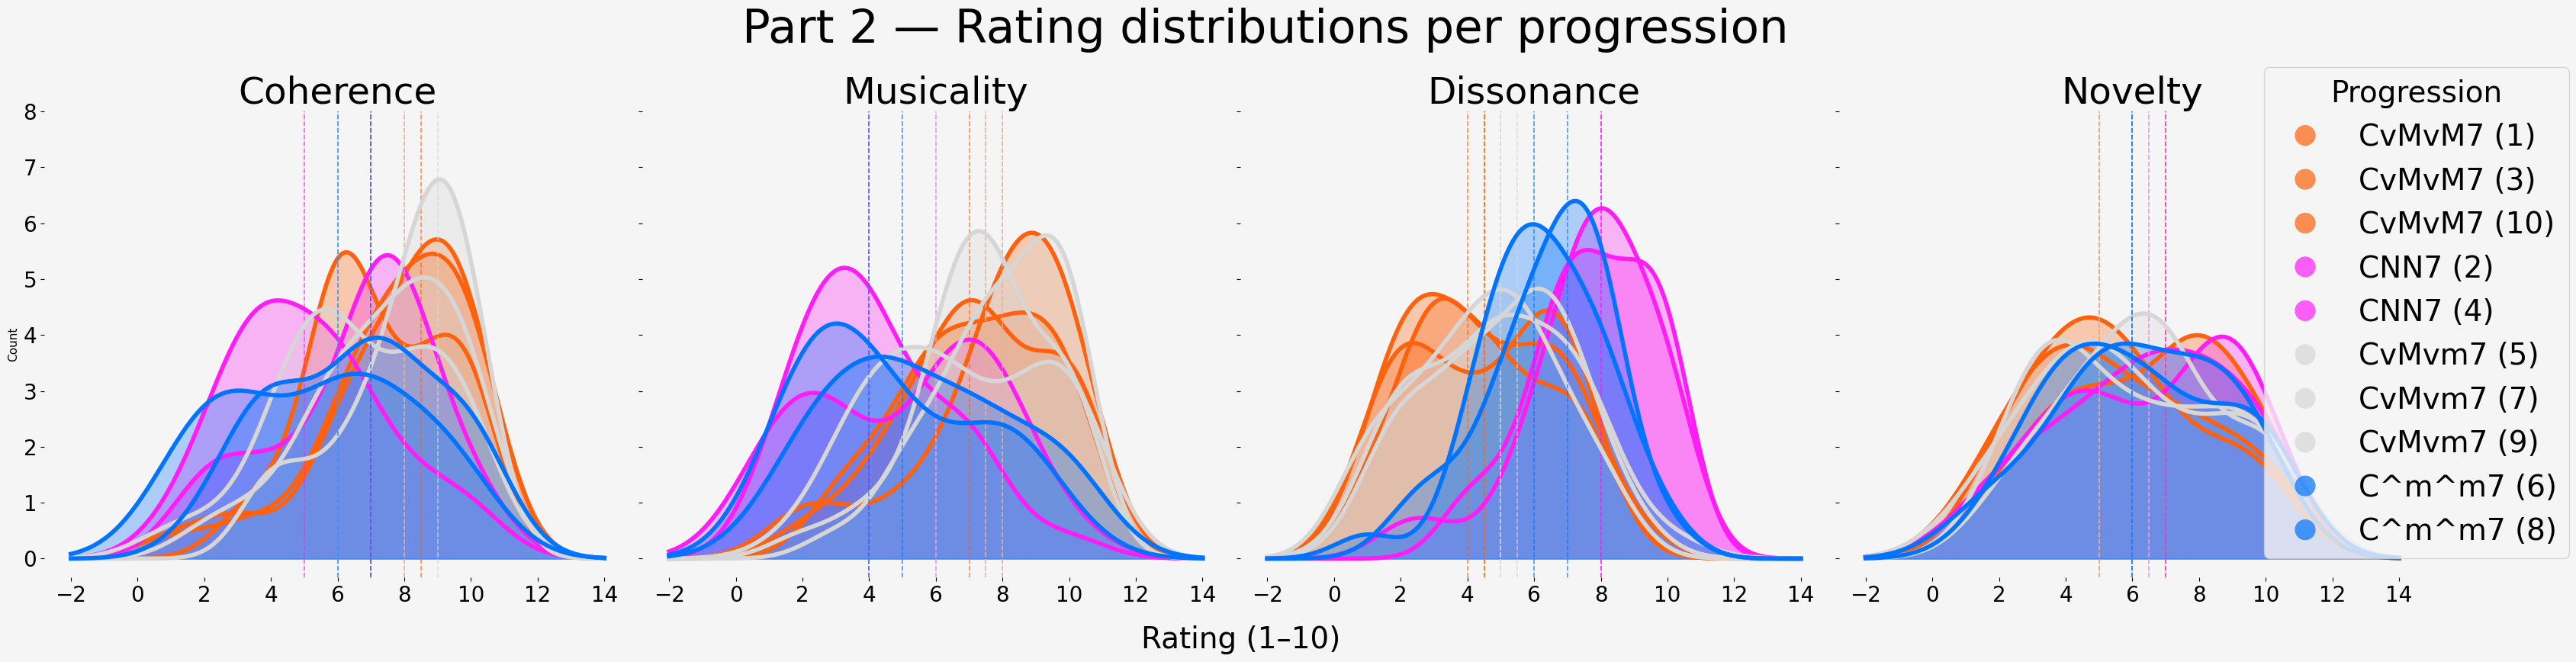

In [9]:
# ---- Part 2: KDE distributions per dimension, colored by progression ----

backgroundGreyColor = "#F5F5F5"
normalSize = 28
titleSize = 44
subtitlesSize = 35
labelSize = 25

progNames = {
    "prog_001": "CvMvM7[I] G#vMvM7/C[VI] C#vMvM7[II] F^m^m7[IV] D#vMm7[III] CvMvM7[I]",
    "prog_002": "CNN7[I] CNN7/vvE[I] ^^Fø^m7[IV] vvAnN7[VI] ^Døvm7[II] ^Gn^m7[V] CNN7[I]",
    "prog_003": "CvMvM7[I] C#vMvM7/F[II] F#vMvM7[V] Bb^m^m7[VII] G#vMm7[VI] CvMvM7[I]",
    "prog_004": "CNN7[I] vvENN7/^G[III] vvAnN7[VI] CNN7[I] ^^Fø^m7[IV] vvBNm7[VII] CNN7[I]",
    "prog_005": "CvMvm7[I] C^m^m7/D#[I] ^Fvm7[IV] vG#maj7[VI] Dø7[II] G^m^m7[V] CvMvm7[I]",
    "prog_006": "C^m^m7[I] vD^m^m7/F[II] vGvM^m7[V] vvBø^m7[VII] D#[III] vAø7[VI] C^m^m7[I]",
    "prog_007": "CvMvm7[I] ^DvMvm7/F#[II] ^GvMvM7[V] B^m^m7[VII] E^m^m7[III] ^Avm7[VI] CvMvm7[I]",
    "prog_008": "C^m^m7[I] CvM^m7/vE[I] vvF#ø^m7[IV] vA^m^m7[VI] vDvM^m7[II] G^mN7[V] C^m^m7[I]",
    "prog_009": "CvMvm7[I] G#vMvm7/C[VI] C#vMvM7[II] F^m^m7[IV] Bb^m^m7[VII] D#vm7[III] CvMvm7[I]",
    "prog_010": "CvMvM7[I] D#vMvM7/G[III] G#vMvM7[VI] C^m^m7[I] ^BbvMm7[VII] CvMvM7[I]",
}

palette = {
    "prog_001": "#FF610C", "prog_003": "#FF610C", "prog_010": "#FF610C",  # Major
    "prog_002": "#FF1CF7", "prog_004": "#FF1CF7",  # Neutral
    "prog_005": "#D6D6D6", "prog_007": "#D6D6D6", "prog_009": "#D6D6D6",  # Dominant
    "prog_006": "#0073FF", "prog_008": "#0073FF",  # Minor
}

prog_to_type = {
    'prog_001': 'Major',   'prog_003': 'Major',   'prog_010': 'Major',
    'prog_002': 'Neutral', 'prog_004': 'Neutral',
    'prog_006': 'Minor',   'prog_008': 'Minor',
    'prog_005': 'Dominant','prog_007': 'Dominant', 'prog_009': 'Dominant',
}

# Build per-progression, per-participant pivot from flat data
p2_flat = part2_raw.copy()
p2_flat['prog'] = p2_flat['progression_id']

for col in ['coherence_rating', 'musicality_rating', 'dissonance_rating', 'novelty_rating']:
    p2_flat[col] = pd.to_numeric(p2_flat[col], errors='coerce')

p2_flat.rename(columns={
    'coherence_rating': 'coherence',
    'musicality_rating': 'musicality',
    'dissonance_rating': 'dissonance',
    'novelty_rating': 'novelty',
}, inplace=True)

metrics = ['coherence', 'musicality', 'dissonance', 'novelty']
pair_df = p2_flat[['participant_id', 'prog'] + metrics].copy()
pdf = pair_df.dropna(subset=metrics).copy()
pdf['chord_type'] = pdf['prog'].map(prog_to_type)

# KDE plot
if len(pdf) > 1:
    prog_order = [
        "prog_001", "prog_003", "prog_010",
        "prog_002", "prog_004",
        "prog_005", "prog_007", "prog_009",
        "prog_006", "prog_008",
    ]
    prog_order = [p for p in prog_order if p in pdf['prog'].unique()]

    prog_short = {
        p: progNames[p].split("[")[0] + " (" + p.replace("prog_", "").lstrip("0") + ")"
        for p in prog_order
    }

    fig, axes = plt.subplots(1, len(metrics), figsize=(8 * len(metrics), 8), sharey=True)
    fig.patch.set_facecolor(backgroundGreyColor)

    for ax, metric in zip(axes, metrics):
        ax.set_facecolor(backgroundGreyColor)
        for spine in ax.spines.values():
            spine.set_visible(False)
        for prog in prog_order:
            subset = pdf.loc[pdf['prog'] == prog, metric].dropna()
            if len(subset) > 1:
                from scipy.stats import gaussian_kde
                kde = gaussian_kde(subset)
                xs = np.linspace(-2, 14, 300)
                ys = kde(xs) * len(subset)
                ax.plot(xs, ys, color=palette[prog], linewidth=4, label=prog_short[prog])
                ax.fill_between(xs, ys, alpha=0.3, color=palette[prog])
            elif len(subset) == 1:
                ax.axvline(subset.values[0], color=palette[prog], linewidth=2,
                           alpha=0.8, label=prog_short[prog])
            if len(subset):
                med = subset.median()
                ax.axvline(med, color=palette[prog], linewidth=1.2,
                           linestyle='--', alpha=0.7)
        ax.set_title(metric.capitalize(), fontsize=subtitlesSize)
        ax.set_xlabel('')
        ax.tick_params(labelsize=20)
        y_max = int(np.ceil(ax.get_ylim()[1]))
        ax.set_yticks(range(0, y_max + 1))

    axes[0].set_ylabel('Count')
    fig.text(0.51, -0.05, 'Rating (1\u201310)', ha='center', fontsize=normalSize)

    from matplotlib.patches import Circle
    from matplotlib.legend_handler import HandlerPatch

    class _HandlerCircle(HandlerPatch):
        def create_artists(self, legend, orig_handle, xdescent, ydescent,
                           width, height, fontsize, trans):
            radius = min(width, height) / 2
            centre = (0.5 * width - 0.5 * xdescent, 0.5 * height - 0.5 * ydescent)
            circ = Circle(centre, radius)
            self.update_prop(circ, orig_handle, legend)
            circ.set_transform(trans)
            return [circ]

    _, labels = axes[0].get_legend_handles_labels()
    handles = [Circle((0, 0), 1, facecolor=palette[prog_order[i]], alpha=0.7)
               for i in range(len(labels))]
    for ax in axes:
        ax.get_legend().remove() if ax.get_legend() else None
    leg = fig.legend(handles, labels, title='Progression', loc='center right',
                     bbox_to_anchor=(1.06, 0.5), fontsize=normalSize,
                     title_fontsize=normalSize, handler_map={Circle: _HandlerCircle()})
    leg.get_frame().set_facecolor(backgroundGreyColor)
    fig.suptitle('Part 2 \u2014 Rating distributions per progression',
                 fontsize=titleSize, y=1.0, x=0.52)
    plt.tight_layout()
    fig.savefig('Figures/Part_2_Rating.png', dpi=200, bbox_inches='tight',
                facecolor=fig.get_facecolor())
    plt.show()

    print('\nProgression key:')
    for pname in prog_order:
        num = pname.replace('prog_', '').lstrip('0') or '0'
        print(f'  {num}: {progNames.get(pname, "")}')

/var/folders/k2/flh0b7xj6mv_tf6gpxphqm9m0000gn/T/ipykernel_74479/1263996313.py:58: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


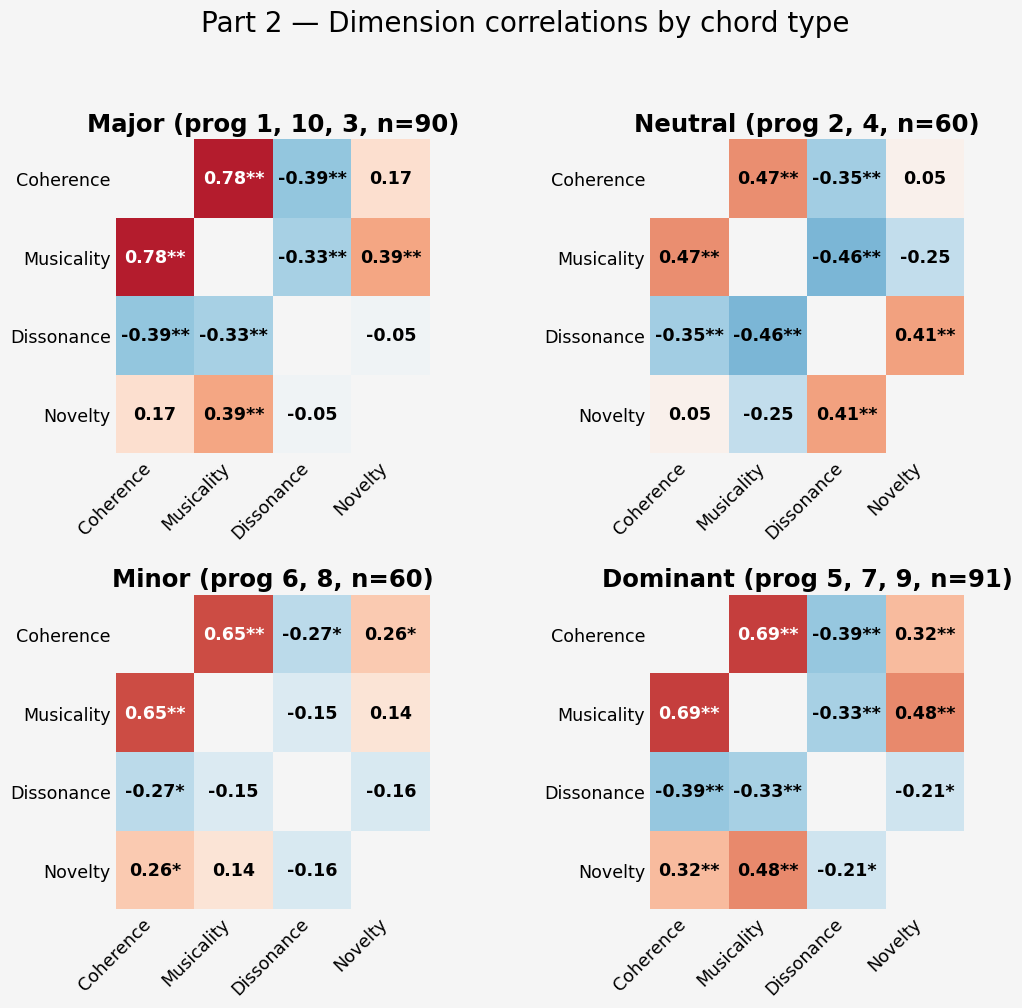


  Major (n=90)
                  Coherence    Musicality    Dissonance       Novelty
    Coherence     1.000**       0.784**      -0.395**       0.166    
   Musicality     0.784**       1.000**      -0.334**       0.395**  
   Dissonance    -0.395**      -0.334**       1.000**      -0.045    
      Novelty     0.166         0.395**      -0.045         1.000**  

  Neutral (n=60)
                  Coherence    Musicality    Dissonance       Novelty
    Coherence     1.000**       0.467**      -0.345**       0.048    
   Musicality     0.467**       1.000**      -0.458**      -0.247    
   Dissonance    -0.345**      -0.458**       1.000**       0.410**  
      Novelty     0.048        -0.247         0.410**       1.000**  

  Minor (n=60)
                  Coherence    Musicality    Dissonance       Novelty
    Coherence     1.000**       0.652**      -0.273*        0.265*   
   Musicality     0.652**       1.000**      -0.145         0.140    
   Dissonance    -0.273*       -0.145   

In [ ]:
# ---- Part 2: Inter-dimension correlations by chord type ----
dims = ['coherence', 'musicality', 'dissonance', 'novelty']
type_colors = {
    'Major': '#FF610C', 'Neutral': '#FF1CF7',
    'Minor': '#0073FF', 'Dominant': '#D6D6D6',
}
chord_types = ['Major', 'Neutral', 'Minor', 'Dominant']
n_dims = len(dims)

import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(12, 10))
fig.patch.set_facecolor(backgroundGreyColor)
gs = gridspec.GridSpec(2, 2, hspace=0.45, wspace=0.35)

for idx, ct in enumerate(chord_types):
    ax = fig.add_subplot(gs[idx])
    ax.set_facecolor(backgroundGreyColor)
    sub = pdf[pdf['chord_type'] == ct]
    rho_mat = np.zeros((n_dims, n_dims))
    pval_mat = np.zeros((n_dims, n_dims))
    for i, d1 in enumerate(dims):
        for j, d2 in enumerate(dims):
            if len(sub) > 2:
                rho_mat[i, j], pval_mat[i, j] = sp_stats.spearmanr(sub[d1], sub[d2])
    im = ax.pcolormesh(np.arange(n_dims + 1) - 0.5, np.arange(n_dims + 1) - 0.5,
                       rho_mat, cmap='RdBu_r', vmin=-1, vmax=1,
                       edgecolors='none', linewidth=0)
    for k in range(n_dims):
        ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1,
                                    facecolor=backgroundGreyColor, edgecolor=backgroundGreyColor,
                                    linewidth=0, zorder=2))
    ax.set_xlim(-0.5, n_dims - 0.5)
    ax.set_ylim(n_dims - 0.5, -0.5)
    ax.set_aspect('equal')
    ax.set_xticks(range(n_dims))
    ax.set_yticks(range(n_dims))
    ax.set_xticklabels([d.capitalize() for d in dims], rotation=45, ha='right', fontsize=normalSize * 0.45)
    ax.set_yticklabels([d.capitalize() for d in dims], fontsize=normalSize * 0.45)
    for i in range(n_dims):
        for j in range(n_dims):
            if i == j:
                continue
            sig = '**' if pval_mat[i, j] < 0.01 else '*' if pval_mat[i, j] < 0.05 else ''
            ax.text(j, i, f"{rho_mat[i, j]:.2f}{sig}", ha='center', va='center',
                    fontsize=normalSize * 0.45, fontweight='bold',
                    color='white' if abs(rho_mat[i, j]) > 0.5 else 'black')
    progs_in_type = [p for p, t in prog_to_type.items() if t == ct]
    prog_nums = ', '.join(sorted(p.replace('prog_', '').lstrip('0') for p in progs_in_type))
    ax.set_title(f'{ct} (prog {prog_nums}, n={len(sub)})',
                 fontsize=subtitlesSize * 0.5, fontweight='bold')
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle('Part 2 — Dimension correlations by chord type',
             fontsize=20, y=1.01)
plt.tight_layout()
plt.show()

# Print correlation tables
for ct in chord_types:
    sub = pdf[pdf['chord_type'] == ct]
    print(f"\n{'='*60}")
    print(f"  {ct} (n={len(sub)})")
    print(f"{'='*60}")
    rho_mat = np.zeros((n_dims, n_dims))
    pval_mat = np.zeros((n_dims, n_dims))
    for i, d1 in enumerate(dims):
        for j, d2 in enumerate(dims):
            if len(sub) > 2:
                rho_mat[i, j], pval_mat[i, j] = sp_stats.spearmanr(sub[d1], sub[d2])
    header = f"{'':>13}" + "".join(f"{d.capitalize():>14}" for d in dims)
    print(header)
    for i, d1 in enumerate(dims):
        row_str = f"{d1.capitalize():>13}"
        for j in range(n_dims):
            sig = '**' if pval_mat[i, j] < 0.01 else '*' if pval_mat[i, j] < 0.05 else ''
            row_str += f"{rho_mat[i, j]:>10.3f}{sig:<4}"
        print(row_str)

# Musicality ranking
prog_music = (
    pdf.groupby('prog')['musicality']
    .agg(['mean', 'median', 'std', 'count'])
    .sort_values('mean')
    .reset_index()
)
prog_music['num'] = prog_music['prog'].apply(lambda p: p.replace('prog_', '').lstrip('0') or '0')
prog_music['description'] = prog_music['prog'].map(progNames)
prog_music['chord_type'] = prog_music['prog'].map(prog_to_type)

print("\n\nMusicality by progression (ascending):\n")
print(f"{'Prog':>5}  {'Type':<10}  {'Mean':>6}  {'Med':>5}  {'Std':>5}  {'N':>3}  Description")
print("─" * 110)
for _, r in prog_music.iterrows():
    print(f"{r['num']:>5}  {r['chord_type']:<10}  {r['mean']:>6.2f}  {r['median']:>5.1f}  {r['std']:>5.2f}  {int(r['count']):>3}  {r['description']}")

low = prog_music.iloc[0]
high = prog_music.iloc[-1]
print(f"\nLowest musicality:  Prog {low['num']} (mean={low['mean']:.2f})")
print(f"Highest musicality: Prog {high['num']} (mean={high['mean']:.2f})")

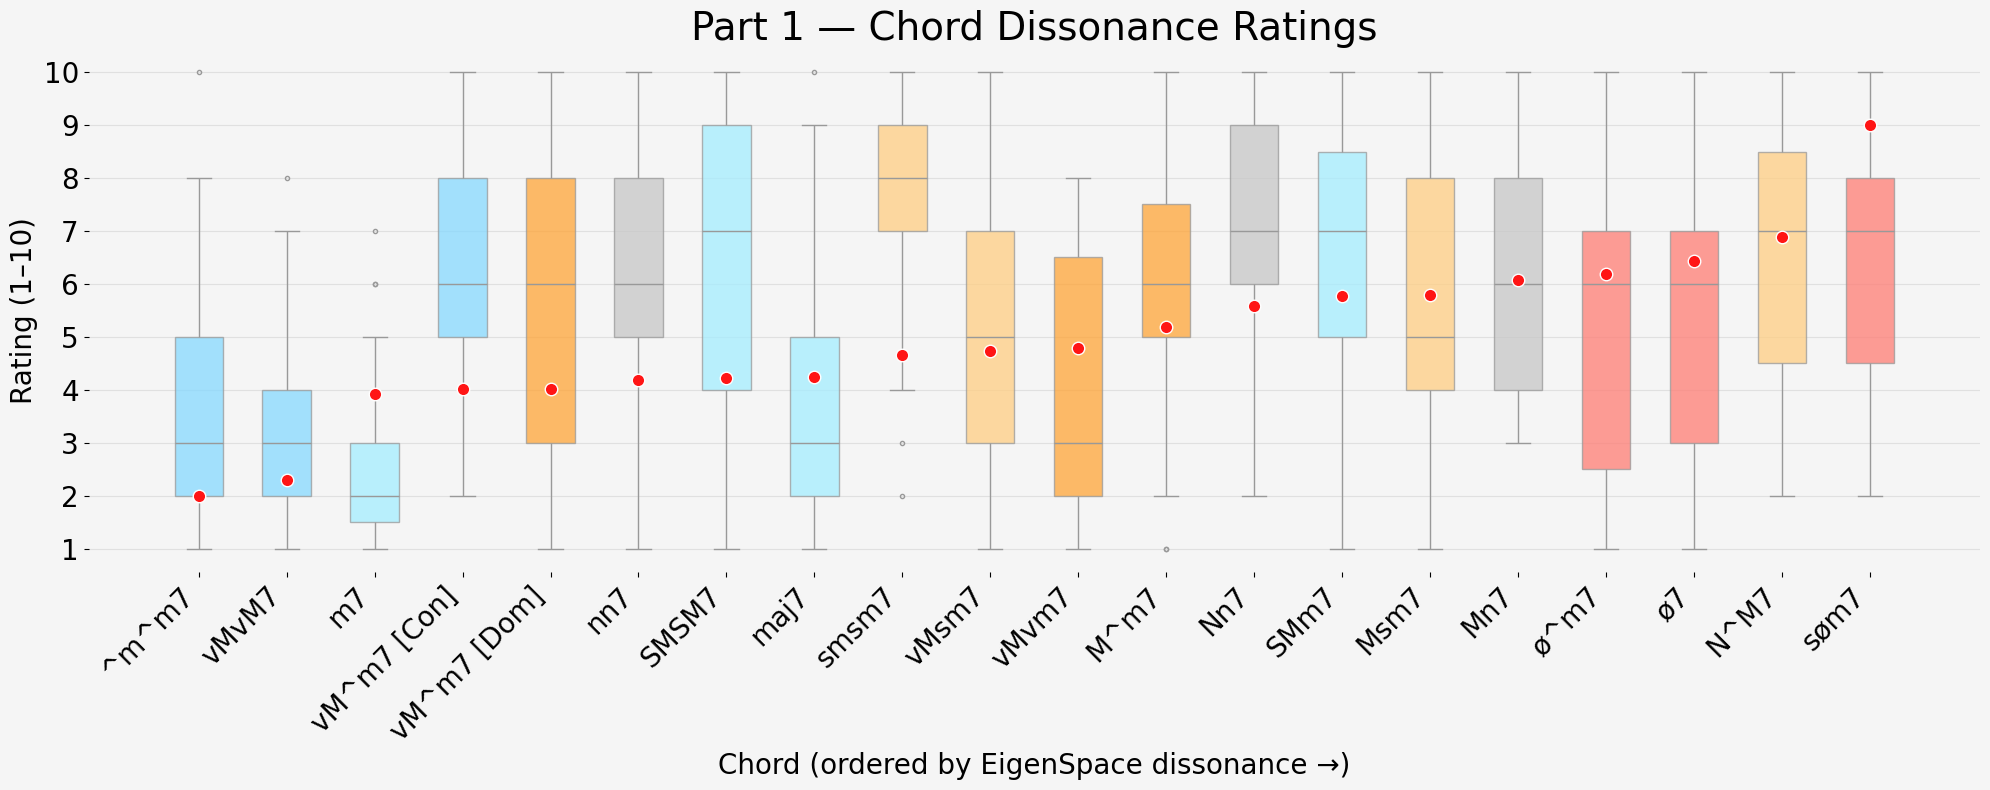


Perceived dissonance (boxplot) vs EigenSpace dissonance (red dots, scaled 2–9)
Spearman ρ = 0.421  (p = 0.0647)
Pearson  r = 0.530  (p = 0.0162)

EigenSpace D range: [11.587, 17.806] → scaled to [2, 9]

 #  Chord     Category           Eigen D   Scaled   Perceived     Std
────────────────────────────────────────────────────────────────────────
 3  ^m^m7     Consonant           11.587     2.00        3.55    2.41
 1  vMvM7     Consonant           11.855     2.30        3.19    1.74
 7  m7        Intermediate        13.287     3.91        2.52    1.57
 2  vM^m7     Consonant           13.380     4.02        6.42    2.03
16  vM^m7     Dominant            13.380     4.02        5.19    2.79
10  nn7       Neutral             13.526     4.18        5.84    2.42
 4  SMSM7     Intermediate        13.556     4.22        6.58    2.67
 6  maj7      Intermediate        13.584     4.25        3.97    2.56
14  smsm7     Less_consonant      13.943     4.65        7.52    1.98
12  vMsm7     Less_cons

In [ ]:
# ---- Compute EigenSpace dissonance for all 20 listening test chords ----

def dissmeasure(fvec, amp):
    idx = np.argsort(fvec)
    fr = np.asarray(fvec)[idx]
    am = np.asarray(amp)[idx]
    Dstar, S1, S2 = 0.24, 0.0207, 18.96
    C1, C2, A1, A2 = 5.0, -5.0, -3.51, -5.75
    ii, jj = np.triu_indices(len(fr), k=1)
    Fmin = fr[ii]
    Fdif = fr[jj] - Fmin
    S = Dstar / (S1 * Fmin + S2)
    a = np.minimum(am[ii], am[jj])
    SFdif = S * Fdif
    return np.sum(a * (C1 * np.exp(A1 * SFdif) + C2 * np.exp(A2 * SFdif)))

def r53(steps):
    return 2 ** (steps / 53)

BASE_FREQ = 220.0
NUM_HARMONICS = 6

CHORD_COLLECTION = [
    ("Consonant",      "vMvM7",  r53(17), r53(31), r53(48)),
    ("Consonant",      "vM^m7",  r53(17), r53(31), r53(45)),
    ("Consonant",      "^m^m7",  r53(14), r53(31), r53(45)),
    ("Intermediate",   "SMSM7",  r53(20), r53(31), r53(51)),
    ("Intermediate",   "SMm7",   r53(20), r53(31), r53(44)),
    ("Intermediate",   "maj7",   r53(18), r53(31), r53(49)),
    ("Intermediate",   "m7",     r53(13), r53(31), r53(44)),
    ("Neutral",        "Mn7",    r53(18), r53(31), r53(46)),
    ("Neutral",        "Nn7",    r53(16), r53(31), r53(46)),
    ("Neutral",        "nn7",    r53(15), r53(31), r53(46)),
    ("Less_consonant", "N^M7",   r53(16), r53(31), r53(50)),
    ("Less_consonant", "vMsm7",  r53(17), r53(31), r53(42)),
    ("Less_consonant", "Msm7",   r53(18), r53(31), r53(42)),
    ("Less_consonant", "smsm7",  r53(11), r53(31), r53(42)),
    ("Dominant",       "M^m7",   r53(18), r53(31), r53(45)),
    ("Dominant",       "vM^m7",  r53(17), r53(31), r53(45)),
    ("Dominant",       "vMvm7",  r53(17), r53(31), r53(43)),
    ("Diminished",     "ø^m7",   r53(14), r53(26), r53(45)),
    ("Diminished",     "søm7",   r53(11), r53(26), r53(44)),
    ("Diminished",     "ø7",     r53(13), r53(26), r53(44)),
]

categoryColors = {
    "Consonant": "#86D9FF",
    "Less_consonant": "#FFCE83",
    "Intermediate": "#A4EDFF",
    "Dominant": "#FFA537",
    "Diminished": "#FF7D74",
    "Neutral": "#C7C7C7",
}

freq_base = BASE_FREQ * np.arange(1, NUM_HARMONICS + 1, dtype=np.float64)
amp_base = np.ones(NUM_HARMONICS, dtype=np.float64)

eigen_rows = []
for i, (cat, name, alpha, beta, gamma) in enumerate(CHORD_COLLECTION, 1):
    f = np.concatenate([freq_base, freq_base * alpha, freq_base * beta, freq_base * gamma])
    a = np.tile(amp_base, 4)
    eigen_rows.append({'chord_num': i, 'chord_category': cat, 'chord_name': name,
                       'eigenspace_dissonance': dissmeasure(f, a)})

eigen_df = pd.DataFrame(eigen_rows)

# Merge with perceived ratings
p1_cmp = part1.copy()
perceived = (p1_cmp.groupby(['chord_num', 'chord_name', 'chord_category'])['rating']
             .agg(['mean', 'std', 'count']).reset_index())

cmp = eigen_df.merge(perceived, on=['chord_num', 'chord_name', 'chord_category'], how='left')

lowNum = 2
highNum = 9
D_min, D_max = cmp['eigenspace_dissonance'].min(), cmp['eigenspace_dissonance'].max()
cmp['eigen_scaled'] = lowNum + (highNum - lowNum) * (cmp['eigenspace_dissonance'] - D_min) / (D_max - D_min)

cmp_sorted = cmp.sort_values('eigenspace_dissonance').reset_index(drop=True)
dup_mask = cmp_sorted['chord_name'].duplicated(keep=False)
cmp_sorted['label'] = cmp_sorted.apply(
    lambda r: f"{r['chord_name']} [{r['chord_category'][:3]}]" if dup_mask.loc[r.name]
    else r['chord_name'], axis=1)
chord_order = cmp_sorted['label'].tolist()

# Spearman & Pearson
r_s, p_s = sp_stats.spearmanr(cmp_sorted['eigenspace_dissonance'], cmp_sorted['mean'])
r_p, p_p = sp_stats.pearsonr(cmp_sorted['eigenspace_dissonance'], cmp_sorted['mean'])

# Map raw ratings to ordered labels for boxplot
num_to_label = dict(zip(cmp_sorted['chord_num'], cmp_sorted['label']))
p1_cmp['label'] = p1_cmp['chord_num'].map(num_to_label)

from matplotlib.patches import Patch

normalSize_plot = 20
titleSize_plot = 28
label_to_cat = dict(zip(cmp_sorted['label'], cmp_sorted['chord_category']))
box_colors = [categoryColors.get(label_to_cat.get(lbl, ''), '#999') for lbl in chord_order]

fig, ax = plt.subplots(figsize=(20, 8))
fig.patch.set_facecolor(backgroundGreyColor)
ax.set_facecolor(backgroundGreyColor)

bp = sns.boxplot(data=p1_cmp, x='label', y='rating', order=chord_order, ax=ax,
                 color='white', width=0.55, fliersize=3)

for patch, col in zip(bp.patches, box_colors):
    patch.set_facecolor(col)
    patch.set_alpha(0.75)

for _, row in cmp_sorted.iterrows():
    x_pos = chord_order.index(row['label'])
    ax.plot(x_pos, row['eigen_scaled'], 'o', color="#FF1515", markersize=9,
            markeredgecolor='white', markeredgewidth=1.0, zorder=5)

ax.set_title("Part 1 — Chord Dissonance Ratings", fontsize=titleSize_plot)
ax.set_xlabel("Chord (ordered by EigenSpace dissonance →)", fontsize=normalSize_plot)
ax.set_ylabel("Rating (1–10)", fontsize=normalSize_plot)
ax.set_xticks(range(len(chord_order)))
ax.set_xticklabels(chord_order, rotation=45, ha="right", fontsize=normalSize_plot)
ax.set_yticks(range(1, 11))
ax.tick_params(axis='y', labelsize=normalSize_plot)
ax.grid(axis='y', alpha=0.3)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
fig.savefig('Figures/Part_1_Dissonance.png', dpi=200, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

print(f"\nPerceived dissonance (boxplot) vs EigenSpace dissonance (red dots, scaled {lowNum}–{highNum})")
print(f"Spearman ρ = {r_s:.3f}  (p = {p_s:.4f})")
print(f"Pearson  r = {r_p:.3f}  (p = {p_p:.4f})")
print(f"\nEigenSpace D range: [{D_min:.3f}, {D_max:.3f}] → scaled to [{lowNum}, {highNum}]")
print(f"\n{'#':>2}  {'Chord':<8}  {'Category':<16}  {'Eigen D':>8}  {'Scaled':>7}  {'Perceived':>10}  {'Std':>6}")
print("─" * 72)
for _, row in cmp_sorted.iterrows():
    print(f"{int(row['chord_num']):>2}  {row['chord_name']:<8}  {row['chord_category']:<16}  "
          f"{row['eigenspace_dissonance']:>8.3f}  {row['eigen_scaled']:>7.2f}  "
          f"{row['mean']:>10.2f}  {row['std']:>6.2f}")

print(f"\n--- Category-level EigenSpace scaled means ---")
cat_means = cmp_sorted.groupby('chord_category')['eigen_scaled'].mean()
for cat in ['Consonant', 'Intermediate', 'Dominant', 'Neutral', 'Less_consonant', 'Diminished']:
    if cat in cat_means.index:
        print(f"  {cat}: {cat_means[cat]:.2f}")

In [ ]:
# Part 1 — Paper-ready results text
most_diss = cmp_sorted.iloc[-1]
least_diss = cmp_sorted.iloc[0]
high_agree = cmp_sorted.nsmallest(3, 'std')
low_agree  = cmp_sorted.nlargest(3, 'std')
cat_means = cmp_sorted.groupby('chord_category')[['mean', 'std', 'eigen_scaled']].mean()
overall_min = cmp_sorted['mean'].min()
overall_max = cmp_sorted['mean'].max()

print("=" * 70)
print("PART 1 RESULTS — TEXT FOR PAPER")
print("=" * 70)
print()
print(f"N = {part1['participant_id'].nunique()} participants rated {len(cmp_sorted)} isolated 53-TET seventh chords")
print(f"on a dissonance scale from 1 (very consonant) to 10 (very dissonant).")
print()
print(f"Perceived mean ratings ranged from {overall_min:.2f} to {overall_max:.2f}.")
print(f"Lowest perceived dissonance: {least_diss['chord_name']} ({least_diss['chord_category']}) — M = {least_diss['mean']:.2f}, SD = {least_diss['std']:.2f}")
print(f"Highest perceived dissonance: {most_diss['chord_name']} ({most_diss['chord_category']}) — M = {most_diss['mean']:.2f}, SD = {most_diss['std']:.2f}")
print()
print(f"Spearman correlation (per-chord mean perceived vs EigenSpace dissonance):")
print(f"  ρ = {r_s:.3f}, p = {p_s:.4f}")
print(f"Pearson correlation:")
print(f"  r = {r_p:.3f}, p = {p_p:.4f}")
print()
print(f"EigenSpace dissonance range: [{D_min:.3f}, {D_max:.3f}], linearly mapped to [{lowNum}, {highNum}]")
print()
print("Highest inter-rater agreement (lowest SD):")
for _, r in high_agree.iterrows():
    print(f"  {r['chord_name']} ({r['chord_category']}): M = {r['mean']:.2f}, SD = {r['std']:.2f}")
print()
print("Lowest inter-rater agreement (highest SD):")
for _, r in low_agree.iterrows():
    print(f"  {r['chord_name']} ({r['chord_category']}): M = {r['mean']:.2f}, SD = {r['std']:.2f}")
print()
print("Category-level means:")
for cat in ['Consonant', 'Intermediate', 'Neutral', 'Less_consonant', 'Dominant', 'Diminished']:
    if cat in cat_means.index:
        row = cat_means.loc[cat]
        print(f"  {cat}: perceived M = {row['mean']:.2f}, EigenSpace scaled = {row['eigen_scaled']:.2f}")

PART 1 RESULTS — TEXT FOR PAPER

N = 31 participants rated 20 isolated 53-TET seventh chords
on a dissonance scale from 1 (very consonant) to 10 (very dissonant).

Perceived mean ratings ranged from 2.52 to 7.52.
Lowest perceived dissonance: ^m^m7 (Consonant) — M = 3.55, SD = 2.41
Highest perceived dissonance: søm7 (Diminished) — M = 6.48, SD = 2.29

Spearman correlation (per-chord mean perceived vs EigenSpace dissonance):
  ρ = 0.421, p = 0.0647
Pearson correlation:
  r = 0.530, p = 0.0162

EigenSpace dissonance range: [11.587, 17.806], linearly mapped to [2, 9]

Highest inter-rater agreement (lowest SD):
  m7 (Intermediate): M = 2.52, SD = 1.57
  vMvM7 (Consonant): M = 3.19, SD = 1.74
  smsm7 (Less_consonant): M = 7.52, SD = 1.98

Lowest inter-rater agreement (highest SD):
  vM^m7 (Dominant): M = 5.19, SD = 2.79
  ø7 (Diminished): M = 5.23, SD = 2.69
  vMsm7 (Less_consonant): M = 5.03, SD = 2.69

Category-level means:
  Consonant: perceived M = 4.39, EigenSpace scaled = 2.77
  Interm

In [ ]:
# Deep dive: vM^m7 [Con] (chord #2) vs vM^m7 [Dom] (chord #16)
focus = p1_cmp[p1_cmp['chord_num'].isin([2, 16])].copy()

print("=== vM^m7: Consonant (#2) vs Dominant (#16) ===\n")
for cn in [2, 16]:
    sub = focus[focus['chord_num'] == cn]
    cat = sub['chord_category'].iloc[0]
    print(f"Chord #{cn} ({cat}):")
    for _, r in sub.iterrows():
        print(f"  participant {r['participant_id']:>2}: rating={int(r['rating']):>2}")
    print(f"  → mean={sub['rating'].mean():.2f}, std={sub['rating'].std():.2f}\n")

print("=== All Consonant category individual ratings ===\n")
cons = p1_cmp[p1_cmp['chord_category'] == 'Consonant']
for cn in sorted(cons['chord_num'].unique()):
    sub = cons[cons['chord_num'] == cn]
    nm = sub['chord_name'].iloc[0]
    ratings = sub['rating'].tolist()
    print(f"  #{int(cn):>2} {nm:<8}: {ratings}  mean={np.mean(ratings):.2f}")

=== vM^m7: Consonant (#2) vs Dominant (#16) ===

Chord #2 (Consonant):
  participant  1: rating= 9
  participant  2: rating= 7
  participant  3: rating= 6
  participant  4: rating= 9
  participant  5: rating= 5
  participant  6: rating= 6
  participant  7: rating= 8
  participant  8: rating= 5
  participant  9: rating= 5
  participant 10: rating= 5
  participant 11: rating= 6
  participant 12: rating= 4
  participant 13: rating= 9
  participant 14: rating= 2
  participant 15: rating= 9
  participant 16: rating= 4
  participant 17: rating= 8
  participant 18: rating= 9
  participant 19: rating= 5
  participant 20: rating= 8
  participant 21: rating= 7
  participant 22: rating= 4
  participant 23: rating= 7
  participant 24: rating= 5
  participant 25: rating= 6
  participant 26: rating= 3
  participant 27: rating= 8
  participant 28: rating= 8
  participant 29: rating=10
  participant 30: rating= 7
  participant 31: rating= 5
  → mean=6.42, std=2.03

Chord #16 (Dominant):
  participant 

In [ ]:
# EigenSpace dissonance values for all 20 chords
print("EigenSpace Plomp-Levelt dissonance (base_freq=220 Hz, 6 harmonics, flat amp)\n")
print(f"{'#':>2}  {'Category':<16}  {'Name':<8}  {'D':>8}")
print("─" * 42)
for _, row in eigen_df.iterrows():
    print(f"{int(row['chord_num']):>2}  {row['chord_category']:<16}  {row['chord_name']:<8}  {row['eigenspace_dissonance']:>8.4f}")

EigenSpace Plomp-Levelt dissonance (base_freq=220 Hz, 6 harmonics, flat amp)

 #  Category          Name             D
──────────────────────────────────────────
 1  Consonant         vMvM7      11.8554
 2  Consonant         vM^m7      13.3802
 3  Consonant         ^m^m7      11.5871
 4  Intermediate      SMSM7      13.5564
 5  Intermediate      SMm7       14.9322
 6  Intermediate      maj7       13.5842
 7  Intermediate      m7         13.2874
 8  Neutral           Mn7        15.2091
 9  Neutral           Nn7        14.7639
10  Neutral           nn7        13.5257
11  Less_consonant    N^M7       15.9230
12  Less_consonant    vMsm7      14.0218
13  Less_consonant    Msm7       14.9591
14  Less_consonant    smsm7      13.9428
15  Dominant          M^m7       14.4169
16  Dominant          vM^m7      13.3802
17  Dominant          vMvm7      14.0603
18  Diminished        ø^m7       15.3089
19  Diminished        søm7       17.8058
20  Diminished        ø7         15.5270


In [ ]:
# Quick interpretation helper for Part 1 dissonance
if len(part1):
    hi = (part1['rating'] >= 7).mean() * 100
    mid = ((part1['rating'] >= 4) & (part1['rating'] <= 6)).mean() * 100
    lo = (part1['rating'] <= 3).mean() * 100
    print(f'Part 1 rating split: high (>=7)={hi:.1f}%, mid (4-6)={mid:.1f}%, low (<=3)={lo:.1f}%')
    print('\nPer-chord medians (lowest to highest):')
    print(part1.groupby('chord_name')['rating'].median().sort_values().to_string())

Part 1 rating split: high (>=7)=39.0%, mid (4-6)=31.6%, low (<=3)=29.4%

Per-chord medians (lowest to highest):
chord_name
m7       2.0
maj7     3.0
vMvm7    3.0
vMvM7    3.0
^m^m7    3.0
Msm7     5.0
vMsm7    5.0
vM^m7    6.0
nn7      6.0
M^m7     6.0
Mn7      6.0
ø7       6.0
ø^m7     6.0
SMm7     7.0
søm7     7.0
SMSM7    7.0
Nn7      7.0
N^M7     7.0
smsm7    8.0


In [ ]:
# ---- Participant profile ----
demo = df[df['trial_name'] == 'demographics'].copy()
screening = df[df['trial_name'] == 'screening'].copy()
expertise = df[df['trial_name'] == 'expertise'].copy()

# Completion time per participant (max time_elapsed_ms)
df['time_elapsed_num'] = pd.to_numeric(df['time_elapsed_ms'], errors='coerce')
run_time = df.groupby('participant_id')['time_elapsed_num'].max().reset_index(name='completion_ms')
run_time['completion_min'] = run_time['completion_ms'] / 60000.0

print('Completion time (minutes) per participant:')
print(run_time.sort_values('participant_id').to_string(index=False))
print('\nCompletion time summary (minutes):')
print(run_time['completion_min'].describe().to_string())

# Build participant profile
participant_profile = demo[['participant_id', 'age', 'gender', 'microtonal_experience']].copy()
participant_profile = participant_profile.merge(
    expertise[['participant_id', 'expertise_level']], on='participant_id', how='left')
participant_profile = participant_profile.merge(
    screening[['participant_id', 'selected_progression', 'is_correct']], on='participant_id', how='left')
participant_profile = participant_profile.merge(
    run_time[['participant_id', 'completion_min']], on='participant_id', how='left')

print('\nParticipant profile:')
print(participant_profile.to_string(index=False))

print('\nAge summary:')
ages = pd.to_numeric(participant_profile['age'], errors='coerce')
print(ages.describe().to_string())

print('\nGender counts:')
print(participant_profile['gender'].fillna('missing').value_counts().to_string())

print('\nExpertise counts:')
print(participant_profile['expertise_level'].fillna('missing').value_counts().to_string())

Completion time (minutes) per participant:
participant_id  completion_ms  completion_min
             1        1394059       23.234317
            10         549343        9.155717
            11         592922        9.882033
            12        1056713       17.611883
            13        1585589       26.426483
            14         527347        8.789117
            15        8203998      136.733300
            16         796846       13.280767
            17         767376       12.789600
            18         952340       15.872333
            19         551223        9.187050
             2         695482       11.591367
            20         701050       11.684167
            21         403821        6.730350
            22         934874       15.581233
            23         759872       12.664533
            24         545800        9.096667
            25        1436275       23.937917
            26         551402        9.190033
            27         538660        

In [ ]:
# ---- Paper-ready demographic summary ----
n_participants = len(participant_profile)
ages = pd.to_numeric(participant_profile['age'], errors='coerce')

gender_counts = participant_profile['gender'].fillna('Not reported').astype(str).str.strip()
gender_counts = gender_counts.replace('', 'Not reported').value_counts()

print("=" * 60)
print("  PARTICIPANT DEMOGRAPHICS (for paper)")
print("=" * 60)
print(f"\nNumber of participants: {n_participants}")
print(f"\nAge (n={ages.notna().sum()} reported):")
print(f"  Mean:   {ages.mean():.1f}")
print(f"  SD:     {ages.std():.1f}")
print(f"  Median: {ages.median():.1f}")
print(f"  Range:  {ages.min():.0f}–{ages.max():.0f}")

print(f"\nGender:")
for g, count in gender_counts.items():
    pct = 100 * count / n_participants
    print(f"  {g}: {count} ({pct:.1f}%)")

exp = participant_profile['expertise_level'].fillna('Not reported').astype(str).str.strip()
exp = exp.replace('', 'Not reported').value_counts()
print(f"\nMusical expertise (self-reported):")
for e, count in exp.items():
    pct = 100 * count / n_participants
    print(f"  {e}: {count} ({pct:.1f}%)")

ct = participant_profile['completion_min'].dropna()
print(f"\nCompletion time (minutes):")
print(f"  Mean:   {ct.mean():.1f}")
print(f"  SD:     {ct.std():.1f}")
print(f"  Median: {ct.median():.1f}")
print(f"  Range:  {ct.min():.1f}–{ct.max():.1f}")

print("\n" + "=" * 60)
print("  Paper-ready sentence:")
print("=" * 60)
gender_parts = [f"{count} {g.lower()}" for g, count in gender_counts.items()]
gender_str = ", ".join(gender_parts)
print(f"\n\"{n_participants} participants ({gender_str}) took part in the study. "
      f"Their mean age was {ages.mean():.1f} years (SD = {ages.std():.1f}, range {ages.min():.0f}–{ages.max():.0f}). "
      f"The average completion time was {ct.mean():.1f} minutes (SD = {ct.std():.1f}).\"")

  PARTICIPANT DEMOGRAPHICS (for paper)

Number of participants: 31

Age (n=31 reported):
  Mean:   37.7
  SD:     12.9
  Median: 33.0
  Range:  22–80

Gender:
  Male: 22 (71.0%)
  Female: 5 (16.1%)
  Prefer not to say: 2 (6.5%)
  Non-binary: 2 (6.5%)

Musical expertise (self-reported):
  Advanced: I'm proficient in various chord types and their roles in progressions, including modal interchange and secondary dominants.: 13 (41.9%)
  Intermediate: I understand chord roles in progressions and can identify subdominant, dominant, and tonic chords, with some knowledge of more complex chords (seventh chords, diminished, augmented).: 11 (35.5%)
  Beginner: I know basic chord names and can identify major and minor chords but I am less sure about how they function in progressions.: 4 (12.9%)
  Expert: I have a deep understanding of harmony and can innovate with chord progressions and harmonizations, teaching advanced concepts.: 3 (9.7%)

Completion time (minutes):
  Mean:   18.1
  SD:     23.1


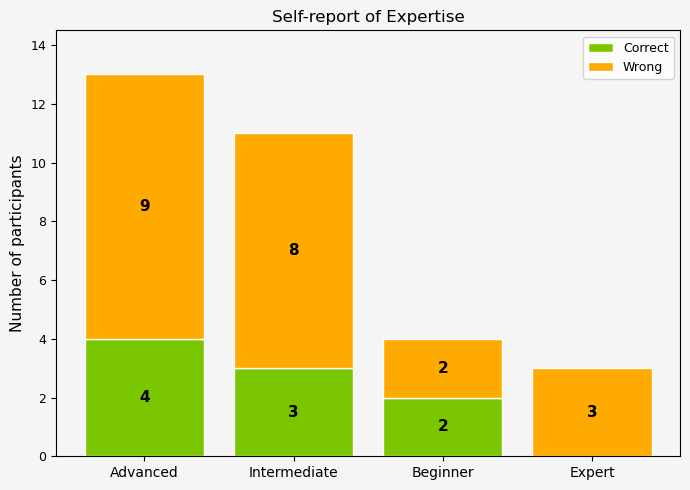


Overall screening: 9/31 correct (29%)


In [ ]:
# ---- Expertise distribution & progression screening accuracy ----
# Irrelevant for the paper as the listeners hasn't been exposed to microtonal modal interchange music or the concept of "expertise" before the experiment, 
# but interesting to report for transparency and future reference.

from matplotlib.patches import Patch

prof = participant_profile.copy()

def _short_expertise(s):
    s = str(s).strip()
    if s in ('', 'nan', 'missing', 'Not reported'):
        return 'N/A'
    return s.split(':')[0].split('.')[0].split(',')[0].strip()

prof['expertise'] = prof['expertise_level'].fillna('missing').apply(_short_expertise)
prof['screening'] = prof['is_correct'].map({'True': 'Correct', 'False': 'Wrong', True: 'Correct', False: 'Wrong'}).fillna('No answer')

exp_order = prof['expertise'].value_counts().index.tolist()

fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor(backgroundGreyColor)
ax.set_facecolor(backgroundGreyColor)

ct_cross = pd.crosstab(prof['expertise'], prof['screening']).reindex(exp_order).fillna(0)
colors_map = {'Correct': "#7AC600", 'Wrong': "#FFAA00", 'No answer': '#CCCCCC'}
bottom = np.zeros(len(exp_order))
for status in ['Correct', 'Wrong', 'No answer']:
    if status in ct_cross.columns:
        vals = ct_cross[status].values
        ax.bar(range(len(exp_order)), vals, bottom=bottom,
               color=colors_map[status], edgecolor='white', label=status)
        for i, v in enumerate(vals):
            if v > 0:
                ax.text(i, bottom[i] + v / 2, str(int(v)),
                        ha='center', va='center', fontsize=11, fontweight='bold',
                        fontfamily='Fira Code')
        bottom += vals

ax.set_xticks(range(len(exp_order)))
ax.set_xticklabels(exp_order, rotation=0, ha='center', fontsize=10, fontfamily='Fira Code')
ax.set_ylabel('Number of participants', fontfamily='Fira Code')
ax.set_title('Self-report of Expertise', fontsize=12, fontfamily='Fira Code')
ax.legend(fontsize=9, loc='upper right', prop={'family': 'Fira Code'})
ax.set_ylim(0, bottom.max() + 1.5)

plt.tight_layout()
fig.savefig('Figures/participants.png', dpi=200, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()

total = len(prof)
n_correct = (prof['screening'] == 'Correct').sum()
print(f"\nOverall screening: {n_correct}/{total} correct ({100*n_correct/total:.0f}%)")

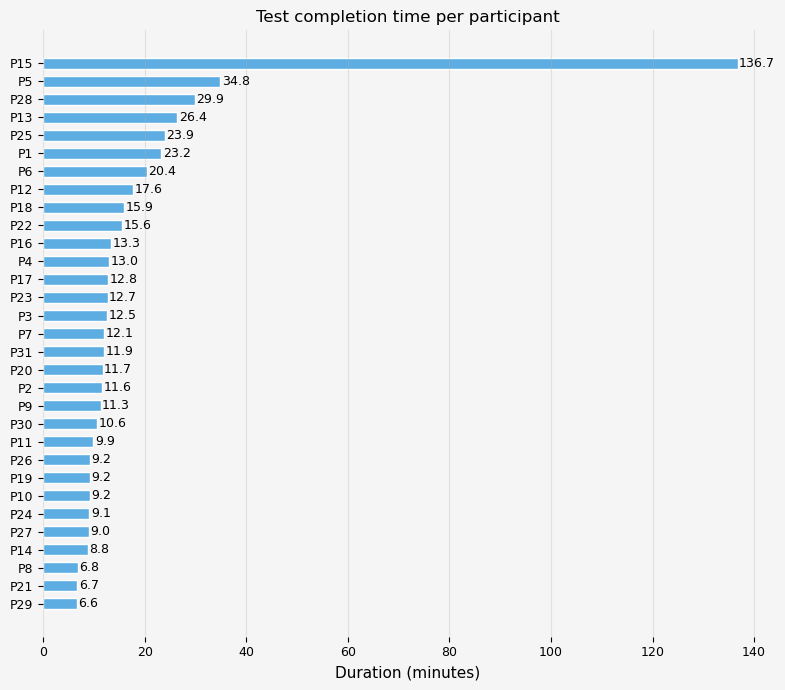


Completion times:
  P29: 6.6 min
  P21: 6.7 min
  P 8: 6.8 min
  P14: 8.8 min
  P27: 9.0 min
  P24: 9.1 min
  P10: 9.2 min
  P19: 9.2 min
  P26: 9.2 min
  P11: 9.9 min
  P30: 10.6 min
  P 9: 11.3 min
  P 2: 11.6 min
  P20: 11.7 min
  P31: 11.9 min
  P 7: 12.1 min
  P 3: 12.5 min
  P23: 12.7 min
  P17: 12.8 min
  P 4: 13.0 min
  P16: 13.3 min
  P22: 15.6 min
  P18: 15.9 min
  P12: 17.6 min
  P 6: 20.4 min
  P 1: 23.2 min
  P25: 23.9 min
  P13: 26.4 min
  P28: 29.9 min
  P 5: 34.8 min
  P15: 136.7 min

  Mean: 18.1 min, Median: 12.1 min


In [ ]:
# ---- Test duration bar chart ----
prof = participant_profile.copy()
prof['completion_min'] = pd.to_numeric(prof['completion_min'], errors='coerce')

fig, ax = plt.subplots(figsize=(8, 7))
fig.patch.set_facecolor(backgroundGreyColor)
ax.set_facecolor(backgroundGreyColor)

prof_sorted = prof.dropna(subset=['completion_min']).sort_values('completion_min')
bars = ax.barh(range(len(prof_sorted)), prof_sorted['completion_min'],
               color='#5DADE2', edgecolor='white', height=0.6)
ax.set_yticks(range(len(prof_sorted)))
ax.set_yticklabels([f"P{r}" for r in prof_sorted['participant_id']], fontsize=9)
for i, v in enumerate(prof_sorted['completion_min']):
    ax.text(v + 0.3, i, f"{v:.1f}", va='center', fontsize=9)
ax.set_xlabel('Duration (minutes)')
ax.set_title('Test completion time per participant', fontsize=12)
ax.grid(axis='x', alpha=0.3)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()

print('\nCompletion times:')
for _, r in prof_sorted.iterrows():
    print(f"  P{r['participant_id']:>2}: {r['completion_min']:.1f} min")
print(f"\n  Mean: {prof_sorted['completion_min'].mean():.1f} min, "
      f"Median: {prof_sorted['completion_min'].median():.1f} min")

In [ ]:
# ---- One-shot summary ----
print('=== Requested answers ===')

ages_list = pd.to_numeric(participant_profile['age'], errors='coerce').dropna().astype(int).tolist()
print('Ages:', ages_list)

print('\nGender counts:')
print(participant_profile['gender'].fillna('missing').value_counts().to_string())

print('\nExpertise:')
print(participant_profile[['participant_id', 'expertise_level']].to_string(index=False))

# Screening
scr = participant_profile[participant_profile['selected_progression'].astype(str).str.strip() != ''].copy()
if len(scr):
    n_correct = (scr['is_correct'].astype(str) == 'True').sum()
    print(f'\nProgression check accuracy: {100 * n_correct / len(scr):.1f}% ({n_correct}/{len(scr)})')
    print(scr[['participant_id', 'selected_progression', 'is_correct', 'expertise_level']].to_string(index=False))

    print('\nAccuracy by expertise:')
    scr['_correct'] = scr['is_correct'].astype(str) == 'True'
    ab = scr.groupby('expertise_level', dropna=False)['_correct'].agg(['count', 'mean'])
    ab['accuracy_pct'] = 100 * ab['mean']
    print(ab[['count', 'accuracy_pct']].sort_values('accuracy_pct', ascending=False).to_string())

    high_mask = scr['expertise_level'].astype(str).str.lower().str.contains('advanced|expert', na=False)
    flagged = scr[high_mask & (~scr['_correct'])]
    print('\nHigh-expertise but failed screening:')
    if len(flagged):
        print(flagged[['participant_id', 'expertise_level', 'selected_progression']].to_string(index=False))
    else:
        print('None in current data.')

=== Requested answers ===
Ages: [32, 51, 46, 47, 25, 42, 33, 22, 27, 33, 26, 49, 31, 29, 50, 36, 24, 58, 26, 30, 44, 46, 26, 32, 80, 27, 28, 51, 51, 29, 37]

Gender counts:
Male                 22
Female                5
Prefer not to say     2
Non-binary            2

Expertise:
participant_id                                                                                                                                                                                      expertise_level
             1                                                                Advanced: I'm proficient in various chord types and their roles in progressions, including modal interchange and secondary dominants.
             2                                                                Advanced: I'm proficient in various chord types and their roles in progressions, including modal interchange and secondary dominants.
             3                                                                Advan

In [ ]:
# ---- Inspect one participant ----
PICK_PARTICIPANT = 3  # Change this to inspect a different participant

pid = str(PICK_PARTICIPANT)
pdata = df[df['participant_id'] == pid]

print(f'=== PARTICIPANT {pid} ===')

# Demographics
d = pdata[pdata['trial_name'] == 'demographics']
if len(d):
    print(f"Age: {d.iloc[0]['age']}")
    print(f"Gender: {d.iloc[0]['gender']}")

# Screening
s = pdata[pdata['trial_name'] == 'screening']
if len(s):
    print(f"Progression answer: {s.iloc[0]['selected_progression']}")
    print(f"Correct: {s.iloc[0]['is_correct']}")

# Part 1
p1_sub = pdata[pdata['trial_name'] == 'chord_dissonance']
print(f'\n=== PART 1: {len(p1_sub)} chord ratings ===')
if len(p1_sub):
    print(p1_sub[['chord_num', 'chord_category', 'chord_name', 'dissonance_rating']].to_string(index=False))

# Part 2
p2_sub = pdata[pdata['trial_name'] == 'chord_progression']
print(f'\n=== PART 2: {len(p2_sub)} progression ratings ===')
if len(p2_sub):
    print(p2_sub[['progression_id', 'coherence_rating', 'musicality_rating',
                   'dissonance_rating', 'novelty_rating']].to_string(index=False))

# Exit
ex = pdata[pdata['trial_name'] == 'exit_survey']
if len(ex):
    print(f"\n=== COMMENTS ===")
    c = ex.iloc[0]['exit_comments']
    d = ex.iloc[0]['exit_difficulties']
    print(f"Comments: {c if c else '(none)'}")
    print(f"Difficulties: {d if d else '(none)'}")

=== PARTICIPANT 3 ===
Age: 46
Gender: Male
Progression answer: ii, V, I, vi
Correct: True

=== PART 1: 20 chord ratings ===
chord_num chord_category chord_name dissonance_rating
       11 Less_consonant       N^M7                 5
       02      Consonant      vM^m7                 6
       06   Intermediate       maj7                 6
       04   Intermediate      SMSM7                 2
       08        Neutral        Mn7                 7
       13 Less_consonant       Msm7                 8
       14 Less_consonant      smsm7                 7
       03      Consonant      ^m^m7                 2
       18     Diminished       ø^m7                 6
       16       Dominant      vM^m7                 7
       09        Neutral        Nn7                 8
       15       Dominant       M^m7                 7
       07   Intermediate         m7                 2
       20     Diminished         ø7                 6
       19     Diminished       søm7                 3
       05   

In [ ]:
# Collect all exit comments and difficulties
exit_data = df[df['trial_name'] == 'exit_survey'].copy()

print("=== All participant comments ===\n")
for _, row in exit_data.sort_values('participant_id').iterrows():
    pid = row['participant_id']
    comment = str(row['exit_comments']).strip()
    difficulty = str(row['exit_difficulties']).strip()
    if comment != '' or difficulty != '':
        print(f"Participant {pid}:")
        print(f"  Comments:     {comment}")
        print(f"  Difficulties: {difficulty}")
        print()

=== All participant comments ===

Participant 1:
  Comments:     Those chord progressions are dope! some hard to tell if dissonant or consonant, as some chords were solid. Does it mix with a standard chord?
  Difficulties: 

Participant 10:
  Comments:     
  Difficulties: I find it difficult to evaluate the novelty of a series of chords, whether they are dissonant or not

Participant 12:
  Comments:     I didn`t understand the symbols. It would be useful to see an explanation. Most progressions are the same across all stimuli; I'm wondering why? cool sound on the progressions, why not the same timber on the chords?
  Difficulties: 

Participant 17:
  Comments:     
  Difficulties: Not sure what surprise is suppose to mean, as I am already anticipating weird chords:)

Participant 2:
  Comments:     Lied about my age.
  Difficulties: 

Participant 20:
  Comments:     I wonder how the chords would sound like with another sound colour (acoustic instruments or synth)
  Difficulties: 

Part